# News Sentiment — Prototype Notebook

A scratch space for trying out the project's building blocks directly, one call at a time: fetching prices and earnings dates from Yahoo Finance, pulling news headlines for a ticker, and scoring those headlines with FinBERT and Qwen side by side.

This notebook isn't a feature — it's for poking at the APIs and sanity-checking behavior before anything new gets wired into `dashboard.py` or `cli.py`. Change `TICKER` below and re-run to explore a different stock.

Run it with `uv run jupyter lab` from the project root, or open it in VS Code / PyCharm with the project's `.venv` selected as the kernel.

In [1]:
from datetime import date

import pandas as pd

from news_sentiment.earnings import YFinanceEarningsSource, is_earnings_soon
from news_sentiment.news_source import YFinanceNewsSource
from news_sentiment.prices import YFinancePriceSource
from news_sentiment.rating import aggregate_rating
from news_sentiment.sentiment import FinbertSentimentScorer, QwenSentimentScorer

TICKER = "NVDA"
HEADLINE_COUNT = 10

## 1. Price history and earnings date (yfinance)

Two layers here: the raw `yfinance` call, so you can see exactly what Yahoo Finance returns, and the project's own wrapper (`YFinancePriceSource`, `YFinanceEarningsSource`) that turns it into clean, typed values.

In [2]:
import yfinance as yf

raw_ticker = yf.Ticker(TICKER)

raw_history = raw_ticker.history(period="5d")[["Close"]]
print("Raw price history (last 5 trading days):")
display(raw_history)

raw_calendar = raw_ticker.calendar
print("\nRaw earnings calendar dict:")
print(raw_calendar)

Raw price history (last 5 trading days):


,Close
Date,
2026-11-02 00:00:00-05:00,202.059998
2026-11-03 00:00:00-05:00,206.690002
2026-11-04 00:00:00-05:00,200.130005
2026-11-05 00:00:00-05:00,181.600006
2026-11-06 00:00:00-05:00,186.639999



Raw earnings calendar dict:
{'Dividend Date': datetime.date(2026, 9, 30), 'Ex-Dividend Date': datetime.date(2026, 9, 9), 'Earnings Date': [datetime.date(2026, 11, 17)], 'Earnings High': 2.7, 'Earnings Low': 2.34, 'Earnings Average': 2.47325, 'Revenue High': 116251000000, 'Revenue Low': 104937000000, 'Revenue Average': 108976833310}


In [3]:
price_source = YFinancePriceSource()
returns = price_source.fetch(TICKER)
print(returns)

earnings_source = YFinanceEarningsSource()
next_earnings = earnings_source.fetch(TICKER)
print(f"\nNext earnings date: {next_earnings}")
print(f"Earnings within 14 days of today? {is_earnings_soon(next_earnings, date.today(), days=14)}")

PriceReturns(ticker='NVDA', price=186.63999938964844, change_1d=0.027753266061345372, change_1w=-0.08795934349924805, change_qtd=-0.1827655863068306, change_ytd=0.0030924402551105344)

Next earnings date: 2026-11-17
Earnings within 14 days of today? True


## 2. News headlines for the ticker

Same two-layer pattern: the raw article dict `yfinance` hands back, then `YFinanceNewsSource.fetch()`, which parses it into a clean list of `Headline` objects.

In [4]:
raw_articles = raw_ticker.get_news(count=3)
print("One raw article dict:")
raw_articles[0] if raw_articles else "No articles returned"

One raw article dict:


{'id': '301bafde-3464-3ac7-b441-fe547d3d02fa',
 'content': {'id': '301bafde-3464-3ac7-b441-fe547d3d02fa',
  'contentType': 'STORY',
  'title': "Obamacare Subsidies Lapsed. Here's Why Health Insurer Stocks Are Watching the New Congress.",
  'description': None,
  'summary': 'More government subsidies for households to pay for health insurance may be introduced, which could help grow Obamacare premiums.',
  'pubDate': '2026-11-08T14:35:00Z',
  'displayTime': '2026-11-08T14:35:00Z',
  'isHosted': True,
  'previewUrl': None,
  'thumbnail': {'originalUrl': 'https://media.zenfs.com/en/motleyfool.com/09a81a610ebc6667f6a9d5d815296270.jpg',
   'originalWidth': 1400,
   'originalHeight': 944,
   'resolutions': [{'url': 'https://media.zenfs.com/en/motleyfool.com/09a81a610ebc6667f6a9d5d815296270.jpg',
     'width': 1400,
     'height': 944,
     'tag': 'original'},
    {'url': 'https://s.yimg.com/lo/mysterio/api/280eb82564c35d14cddb8d77122d7fc00b174e97a29bc3a53efd95ce467bc900/lightyear_networkapi/

In [5]:
news_source = YFinanceNewsSource()
headlines = news_source.fetch(TICKER, count=HEADLINE_COUNT)

headlines_df = pd.DataFrame(
    [{"title": h.title, "publisher": h.publisher, "published_at": h.published_at} for h in headlines]
)
headlines_df

,title,publisher,published_at
0,Obamacare Subsidies Lapsed. Here's Why Health ...,Motley Fool,2026-11-08T14:35:00Z
1,"Dow Jones Futures Loom With Market Damaged, Bi...",Investor's Business Daily,2026-11-08T14:14:55Z
2,Is a Market Crash Coming? Warren Buffett's War...,Motley Fool,2026-11-08T14:09:00Z
3,Should You Forget IonQ and Buy These 2 Quantum...,Motley Fool,2026-11-08T13:57:00Z
4,Morgan Stanley Says $300. Michael Burry Says O...,Motley Fool,2026-11-08T13:50:00Z
5,Prediction: This Glorious Growth Stock Is Goin...,Motley Fool,2026-11-08T13:49:00Z
6,Prediction: This Will Be the Best-Performing A...,Motley Fool,2026-11-08T13:25:00Z
7,These 3 Unstoppable ETFs Could Build a Million...,Motley Fool,2026-11-08T13:04:00Z
8,Elon Musk Says Tesla Will End Cybertruck Produ...,Motley Fool,2026-11-08T12:53:00Z
9,Should You Buy VOO Before the Market Rebounds?,Motley Fool,2026-11-08T12:50:00Z


## 3. Sentiment scoring — FinBERT vs. Qwen

Both scorers implement the same interface (`score_all(headlines) -> list[ScoredHeadline]`) but work completely differently under the hood:

- **FinBERT** is a classifier fine-tuned on financial text — one forward pass per headline returns a label directly, with a calibrated confidence.
- **Qwen** is a general-purpose instruction-following LLM — it's prompted to answer Positive/Negative/Neutral in free text, which then has to be parsed back into a label.

Loading Qwen's weights the first time takes a minute; after that they're cached locally (`~/.cache/huggingface`).

In [6]:
finbert_scorer = FinbertSentimentScorer()
finbert_scored = finbert_scorer.score_all(headlines)

for s in finbert_scored:
    print(f"[{s.sentiment_score:+d}] ({s.confidence:.2f}) {s.headline.title}")

/Users/zhang.xiaoting.apple/github/news_sentiment/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1108 09:39:36.875000 87759 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 22165.83it/s]


[+0] (0.91) Obamacare Subsidies Lapsed. Here's Why Health Insurer Stocks Are Watching the New Congress.
[-1] (0.79) Dow Jones Futures Loom With Market Damaged, Big Winners Broken; Apple, Amazon, Microsoft Strong
[+0] (0.72) Is a Market Crash Coming? Warren Buffett's Warning Is Ringing Loud and Clear.
[+0] (0.93) Should You Forget IonQ and Buy These 2 Quantum Computing Stocks Instead?
[+0] (0.92) Morgan Stanley Says $300. Michael Burry Says Overvalued. Here's Who Is Right About SpaceX Stock.
[+1] (0.86) Prediction: This Glorious Growth Stock Is Going to Soar in 2027
[+1] (0.88) Prediction: This Will Be the Best-Performing AI Stock of 2027
[+0] (0.89) These 3 Unstoppable ETFs Could Build a Million-Dollar Portfolio With Little Effort on Your Part. Here's How.
[+0] (0.77) Elon Musk Says Tesla Will End Cybertruck Production -- Here's Why
[+0] (0.91) Should You Buy VOO Before the Market Rebounds?


In [7]:
qwen_scorer = QwenSentimentScorer()
qwen_scored = qwen_scorer.score_all(headlines)

for s in qwen_scored:
    print(f"[{s.sentiment_score:+d}] {s.headline.title}")

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 9941.20it/s]


[+0] Obamacare Subsidies Lapsed. Here's Why Health Insurer Stocks Are Watching the New Congress.
[+0] Dow Jones Futures Loom With Market Damaged, Big Winners Broken; Apple, Amazon, Microsoft Strong
[+0] Is a Market Crash Coming? Warren Buffett's Warning Is Ringing Loud and Clear.
[+0] Should You Forget IonQ and Buy These 2 Quantum Computing Stocks Instead?
[+0] Morgan Stanley Says $300. Michael Burry Says Overvalued. Here's Who Is Right About SpaceX Stock.
[+1] Prediction: This Glorious Growth Stock Is Going to Soar in 2027
[+1] Prediction: This Will Be the Best-Performing AI Stock of 2027
[+1] These 3 Unstoppable ETFs Could Build a Million-Dollar Portfolio With Little Effort on Your Part. Here's How.
[+0] Elon Musk Says Tesla Will End Cybertruck Production -- Here's Why
[+0] Should You Buy VOO Before the Market Rebounds?


In [8]:
comparison_df = pd.DataFrame(
    [
        {
            "title": f.headline.title,
            "finbert_label": f.label,
            "finbert_score": f.sentiment_score,
            "qwen_label": q.label,
            "qwen_score": q.sentiment_score,
            "agree": f.sentiment_score == q.sentiment_score,
        }
        for f, q in zip(finbert_scored, qwen_scored)
    ]
)
comparison_df

,title,finbert_label,finbert_score,qwen_label,qwen_score,agree
0,Obamacare Subsidies Lapsed. Here's Why Health ...,neutral,0,neutral,0,True
1,"Dow Jones Futures Loom With Market Damaged, Bi...",negative,-1,neutral,0,False
2,Is a Market Crash Coming? Warren Buffett's War...,neutral,0,neutral,0,True
3,Should You Forget IonQ and Buy These 2 Quantum...,neutral,0,neutral,0,True
4,Morgan Stanley Says $300. Michael Burry Says O...,neutral,0,neutral,0,True
5,Prediction: This Glorious Growth Stock Is Goin...,positive,1,positive,1,True
6,Prediction: This Will Be the Best-Performing A...,positive,1,positive,1,True
7,These 3 Unstoppable ETFs Could Build a Million...,neutral,0,positive,1,False
8,Elon Musk Says Tesla Will End Cybertruck Produ...,neutral,0,neutral,0,True
9,Should You Buy VOO Before the Market Rebounds?,neutral,0,neutral,0,True


In [9]:
agreement_rate = comparison_df["agree"].mean()
print(f"FinBERT and Qwen agree on {agreement_rate:.0%} of headlines for {TICKER}.")

FinBERT and Qwen agree on 80% of headlines for NVDA.


## 4. Aggregate rating

`aggregate_rating()` averages a ticker's scored headlines into a single BUY/HOLD/SELL verdict — the same function the CLI and dashboard use.

In [10]:
finbert_rating = aggregate_rating(TICKER, finbert_scored)
qwen_rating = aggregate_rating(TICKER, qwen_scored)

print(f"FinBERT: {finbert_rating.rating} (avg score {finbert_rating.avg_score:+.2f})")
print(f"Qwen:    {qwen_rating.rating} (avg score {qwen_rating.avg_score:+.2f})")

FinBERT: HOLD (avg score +0.10)
Qwen:    BUY (avg score +0.30)


## 5. Visualizing the two models side by side

A quick bar chart makes disagreement easier to spot than scanning the table above.

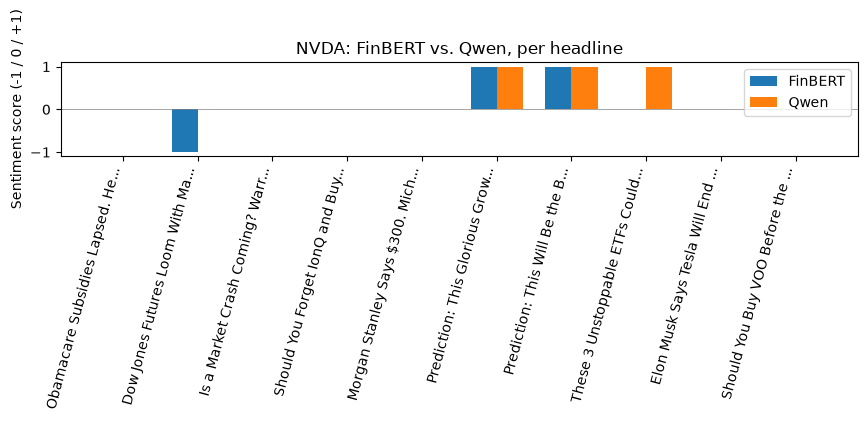

In [11]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(comparison_df))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - width / 2, comparison_df["finbert_score"], width, label="FinBERT")
ax.bar(x + width / 2, comparison_df["qwen_score"], width, label="Qwen")
ax.set_xticks(x)
ax.set_xticklabels(
    [t[:30] + "..." if len(t) > 30 else t for t in comparison_df["title"]], rotation=75, ha="right"
)
ax.set_ylabel("Sentiment score (-1 / 0 / +1)")
ax.set_title(f"{TICKER}: FinBERT vs. Qwen, per headline")
ax.legend()
ax.axhline(0, color="gray", linewidth=0.5)
plt.tight_layout()
plt.show()

## Ideas worth exploring next

Things this prototype surfaces that could become real features:

- **Model disagreement as its own signal.** When FinBERT and Qwen disagree on a headline, that's often a genuinely ambiguous or sarcastic one — worth surfacing in the dashboard rather than averaging it away.
- **Publisher weighting.** Not all sources are equally reliable; a Reuters headline and an obscure blog post currently count the same in `aggregate_rating()`.
- **Recency decay.** A two-week-old headline currently counts as much as one from this morning. A half-life weighting would make the rating more responsive to new information.
- **Backtesting ratings against forward returns.** `prices.py` already computes 1D/1W/QTD/YTD returns — pairing a day's rating with the *next* period's return would start to answer "does this sentiment score actually predict anything?"
- **Earnings-window sentiment drift.** Now that `earnings.py` knows the next earnings date, it'd be interesting to track whether sentiment systematically shifts in the days leading up to a report.
- **A third, larger model.** Qwen2.5-0.5B is tiny and fast but not very capable; swapping in a bigger instruct model (or a FinBERT-tone variant) would show whether scale changes the FinBERT/LLM agreement rate.
- **Rate limiting / caching yfinance calls.** Looping this notebook over a full watchlist quickly will hit Yahoo Finance's informal rate limits — worth building in before scaling this past one ticker at a time.